# Portfolio Allocation Project — Part 1: Data Pipeline

**Goal of this notebook:** download about 22 years of daily prices (January 2005 – October 2026) for 9 ETFs covering different asset classes, convert them to daily log returns, and explore their statistical properties (fat tails, skewness, and how correlations change in crises and across market regimes) before any optimization.

**Output:** `prices.csv` (adjusted prices) and `returns.csv` (daily log returns), which the next notebooks will use.

If `yfinance` or `plotly` aren't installed yet, run this once in a terminal:
```
pip install yfinance plotly nbformat
```

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import plotly.graph_objects as go

## 1. Choose the assets

One ETF per asset class. The order of this list defines the position of each asset in every vector and matrix later on ($\mathbf a$, $\mathbf Y$, $\boldsymbol\mu$, $\Sigma$), so we keep it fixed.

**Why the sample starts in 2005.** The optimizer needs every asset on the same days, so the sample can only start when the youngest ETF exists. GLD (gold) started trading in November 2004, so January 2005 is the earliest common start. An emerging-market local-currency bond ETF (EMLC) was considered, but it only exists since July 2010; we leave it out so that the sample includes the **2008 financial crisis**, the most important stress test for any allocation strategy.

In [2]:
assets = {
    "SPY":  "U.S. large stocks (S&P 500)",
    "IWM":  "U.S. small stocks (Russell 2000)",
    "EFA":  "Developed international stocks",
    "EEM":  "Emerging-market stocks",
    "TLT":  "Long U.S. Treasuries (20+ yr)",
    "IEF":  "Intermediate U.S. Treasuries (7-10 yr)",
    "LQD":  "Investment-grade corporate bonds",
    "GLD":  "Gold",
    "VNQ":  "U.S. real estate (REITs)",
}
tickers = list(assets.keys())
K = len(tickers)

START = "2005-01-01"
END = "2026-10-30"   # yfinance excludes the end date
print(f"K = {K} assets")

K = 9 assets


## 2. Download adjusted prices (or load them if already saved)

`auto_adjust=True` adjusts prices for dividends and splits. This matters a lot for bond ETFs, whose return is mostly dividends.

The download only happens the first time; after that the notebook reads `prices.csv`, so results don't change every time you rerun it.

In [3]:
PRICES_FILE = "prices.csv"

if os.path.exists(PRICES_FILE):
    prices = pd.read_csv(PRICES_FILE, index_col=0, parse_dates=True)
    print("Loaded prices from file.")
else:
    raw = yf.download(tickers, start=START, end=END, auto_adjust=True, progress=False)
    prices = raw["Close"]
    prices.to_csv(PRICES_FILE)
    print("Downloaded and saved prices.")

# yfinance sorts columns alphabetically: put them back in our fixed order
prices = prices[tickers]
prices.tail()

Loaded prices from file.


,SPY,IWM,EFA,EEM,TLT,IEF,LQD,GLD,VNQ
Date,,,,,,,,,
2026-10-23,759.969971,275.750000,102.629997,62.009998,81.339996,91.050003,103.849998,366.609985,92.690002
2026-10-26,765.369995,276.989990,102.910004,61.820000,81.680000,91.120003,104.019997,367.820007,93.169998
2026-10-27,769.659973,280.179993,103.589996,62.520000,81.629997,91.099998,104.300003,372.279999,92.389999
2026-10-28,772.309998,281.290009,103.680000,63.520000,80.989998,90.849998,104.070000,373.510010,91.790001
2026-10-29,769.359985,284.010010,104.349998,62.720001,81.489998,91.250000,104.220001,368.570007,93.870003


## 3. Sanity checks on prices

- Does every ETF start at the beginning of the sample?
- Are there missing values?

In [4]:
checks = pd.DataFrame({
    "first_date": prices.apply(lambda s: s.first_valid_index().date()),
    "last_date": prices.apply(lambda s: s.last_valid_index().date()),
    "missing_values": prices.isna().sum(),
})
print(f"Trading days: {len(prices)}")
checks

Trading days: 5491


,first_date,last_date,missing_values
SPY,2005-01-03,2026-10-29,0
IWM,2005-01-03,2026-10-29,0
EFA,2005-01-03,2026-10-29,0
EEM,2005-01-03,2026-10-29,0
TLT,2005-01-03,2026-10-29,0
IEF,2005-01-03,2026-10-29,0
LQD,2005-01-03,2026-10-29,0
GLD,2005-01-03,2026-10-29,0
VNQ,2005-01-03,2026-10-29,0


## 4. Prices → daily log returns

$r_t = \ln(P_t) - \ln(P_{t-1})$. Each row of `returns` is one realization of the random vector $\mathbf Y$; each column is one asset's history. This is the data matrix $R$ ($T \times K$).

In [5]:
returns = np.log(prices).diff().dropna()
returns.to_csv("returns.csv")
print(f"R has shape {returns.shape}  (T days x K assets)")
returns.head()

R has shape (5490, 9)  (T days x K assets)


,SPY,IWM,EFA,EEM,TLT,IEF,LQD,GLD,VNQ
Date,,,,,,,,,
2005-01-04,-0.012294,-0.021669,-0.019357,-0.031272,-0.010536,-0.006247,-0.005628,-0.006530,-0.015144
2005-01-05,-0.006924,-0.020190,-0.000641,-0.012318,0.005339,0.001654,0.000806,-0.001639,-0.033808
2005-01-06,0.005071,0.005289,0.000000,-0.000680,0.000679,0.000944,0.000716,-0.012261,0.007674
2005-01-07,-0.001434,-0.011180,-0.004499,0.001934,0.002261,-0.000827,-0.000447,-0.007382,-0.002240
2005-01-10,0.004717,0.010124,0.004499,0.001252,0.001581,-0.000117,-0.001702,0.002626,-0.003182


## 5. Summary statistics (annualized)

Daily numbers are tiny and hard to read, so we annualize: mean × 252 and standard deviation × $\sqrt{252}$ (about 252 trading days per year).

We also look at two shape statistics that a normal distribution cannot capture:

- **Skewness**: 0 for a symmetric distribution. Negative values mean the left tail is longer: large losses are more likely than equally large gains.
- **Excess kurtosis**: 0 for a normal distribution. Large positive values mean fat tails, i.e. extreme days happen more often than the Gaussian model assumes.

In [6]:
summary = pd.DataFrame({
    "description": pd.Series(assets),
    "ann_mean_return": returns.mean() * 252,
    "ann_volatility": returns.std() * np.sqrt(252),
    "skewness": returns.skew(),
    "excess_kurtosis": returns.kurt(),
})
summary.round(3)

,description,ann_mean_return,ann_volatility,skewness,excess_kurtosis
SPY,U.S. large stocks (S&P 500),0.103,0.189,-0.304,14.801
IWM,U.S. small stocks (Russell 2000),0.082,0.240,-0.509,6.921
EFA,Developed international stocks,0.060,0.210,-0.352,13.667
EEM,Emerging-market stocks,0.067,0.275,0.023,15.520
TLT,Long U.S. Treasuries (20+ yr),0.029,0.145,0.006,3.459
IEF,Intermediate U.S. Treasuries (7-10 yr),0.030,0.067,0.110,2.700
LQD,Investment-grade corporate bonds,0.037,0.085,-0.448,59.867
GLD,Gold,0.099,0.183,-0.451,6.566
VNQ,U.S. real estate (REITs),0.066,0.284,-0.536,19.032


### Robustness check: excluding the two crises

Sample skewness and kurtosis are driven by a handful of extreme days. The sample contains two extreme episodes:

- the **2008 financial crisis**, from **1 September 2008 to 31 March 2009** (Lehman Brothers' collapse and the market bottom), and
- the **COVID crash**, from **20 February to 30 April 2020** (the crash and the Fed's rescue response).

To see how much each event matters, we recompute kurtosis and skewness excluding each window separately and both together, and then the full summary without either crisis.

In [7]:
gfc = (returns.index >= "2008-09-01") & (returns.index <= "2009-03-31")
covid = (returns.index >= "2020-02-20") & (returns.index <= "2020-04-30")
print(f"2008 crisis window: {gfc.sum()} days, COVID window: {covid.sum()} days")

# How kurtosis and skewness change when each crisis is removed
samples = {
    "full": returns,
    "ex_2008": returns[~gfc],
    "ex_covid": returns[~covid],
    "ex_both": returns[~(gfc | covid)],
}
kurtosis = pd.DataFrame({name: r.kurt() for name, r in samples.items()})
skewness = pd.DataFrame({name: r.skew() for name, r in samples.items()})
print("Excess kurtosis:")
print(kurtosis.round(2))
print()
print("Skewness:")
print(skewness.round(3))

2008 crisis window: 146 days, COVID window: 50 days
Excess kurtosis:
      full  ex_2008  ex_covid  ex_both
SPY  14.80    11.00     13.43     5.30
IWM   6.92     6.29      4.86     2.50
EFA  13.67     8.30     13.01     4.68
EEM  15.52     4.59     15.93     2.72
TLT   3.46     3.55      1.46     1.24
IEF   2.70     2.05      2.18     1.36
LQD  59.87    27.32     65.87     2.72
GLD   6.57     5.33      6.74     5.45
VNQ  19.03    13.75     18.54     7.37

Skewness:
      full  ex_2008  ex_covid  ex_both
SPY -0.304   -0.487    -0.144   -0.265
IWM -0.509   -0.466    -0.291   -0.145
EFA -0.352   -0.632    -0.150   -0.341
EEM  0.023   -0.372     0.159   -0.175
TLT  0.006   -0.049    -0.031   -0.098
IEF  0.110   -0.013     0.090   -0.045
LQD -0.448    0.147    -0.790   -0.156
GLD -0.451   -0.647    -0.469   -0.675
VNQ -0.536   -0.438    -0.306    0.109


The summary without either crisis:

In [8]:
returns_ex = returns[~(gfc | covid)]

summary_ex = pd.DataFrame({
    "description": pd.Series(assets),
    "ann_mean_return": returns_ex.mean() * 252,
    "ann_volatility": returns_ex.std() * np.sqrt(252),
    "skewness": returns_ex.skew(),
    "excess_kurtosis": returns_ex.kurt(),
})
summary_ex.round(3)

,description,ann_mean_return,ann_volatility,skewness,excess_kurtosis
SPY,U.S. large stocks (S&P 500),0.136,0.155,-0.265,5.301
IWM,U.S. small stocks (Russell 2000),0.123,0.209,-0.145,2.501
EFA,Developed international stocks,0.096,0.174,-0.341,4.684
EEM,Emerging-market stocks,0.101,0.226,-0.175,2.715
TLT,Long U.S. Treasuries (20+ yr),0.016,0.137,-0.098,1.243
IEF,Intermediate U.S. Treasuries (7-10 yr),0.023,0.064,-0.045,1.363
LQD,Investment-grade corporate bonds,0.041,0.064,-0.156,2.717
GLD,Gold,0.095,0.173,-0.675,5.453
VNQ,U.S. real estate (REITs),0.122,0.215,0.109,7.365


**Takeaways**

- **The fat tails come mostly from 2008.** Removing COVID alone barely changes kurtosis (and for LQD it even rises, from 59.9 to 65.9), while removing 2008 cuts it sharply: LQD falls to 27.3 and EEM from 15.5 to 4.6. Without both crises, kurtosis drops to between 1.2 and 7.4 for every asset.
- **LQD is the most extreme case.** Its kurtosis of 59.9 comes from a few days in September–October 2008, when investment-grade credit froze (−9.6% on 29 September and +9.3% the next day). Without the two crises it falls to 2.7, close to the Treasuries.
- **Gold is the exception:** its kurtosis barely moves (6.6 → 5.5) and its skewness becomes slightly more negative, so its extreme days are spread across the sample rather than concentrated in the crises.
- **Skewness is unstable.** Its sign changes depending on which crisis is removed (EEM goes from +0.02 to −0.37 without 2008; VNQ from −0.54 to +0.11 without both). It is too sensitive to a few days to be a reliable property of an asset.
- **Without the crises, risk assets look much better** (SPY: mean 10.3% → 13.6%, volatility 18.9% → 15.5%; VNQ: mean 6.6% → 12.2%), while **Treasuries look worse** (TLT: 2.9% → 1.6%). Treasuries earned their best returns exactly during the crises: in the 2008 window TLT gained 15% while SPY lost 37%. Their value as a hedge shows up in crises, not in their average return.

**Implications for the portfolio model**

1. Sample skewness and kurtosis are unstable, since their sign and size depend on a few days. We use them as **diagnostics**, not as criteria to include or exclude assets.
2. Normality is clearly violated, so minimum-variance results should be complemented with tail-risk measures (e.g. CVaR, maximum drawdown) on the final portfolios.
3. Historical mean returns are period-dependent (see TLT). Expected-return inputs to the optimizer should be treated with caution.
4. We do **not** drop the crises when estimating the model: they are exactly the kind of events a robust portfolio must withstand. How much history to use is a separate question, addressed later with rolling estimates.

## 6. Growth of $1 invested in each asset

Since log returns add up over time, $\exp(\text{cumulative sum})$ gives the value of \$1 invested at the start.

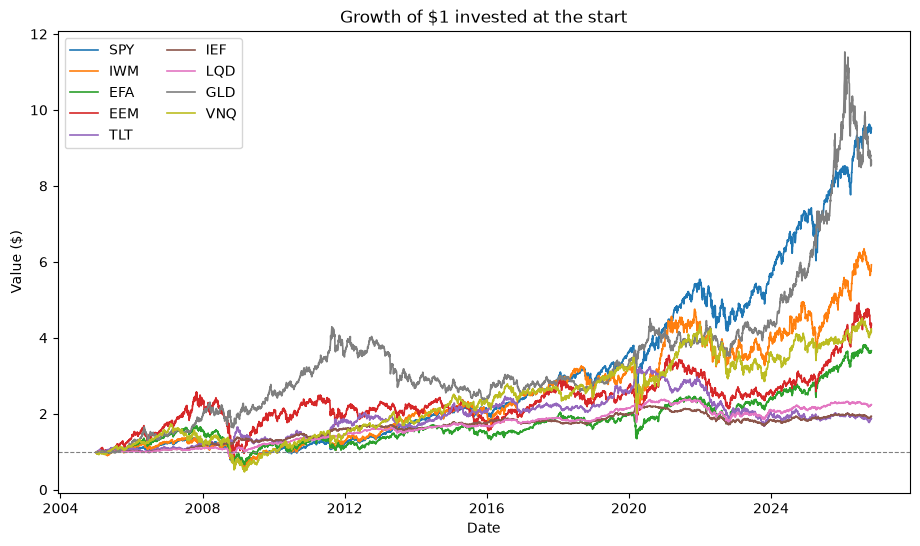

In [9]:
growth = np.exp(returns.cumsum())

fig, ax = plt.subplots(figsize=(11, 6))
for t in tickers:
    ax.plot(growth.index, growth[t], label=t, linewidth=1.2)
ax.axhline(1, color="gray", linewidth=0.8, linestyle="--")
ax.set_title("Growth of $1 invested at the start")
ax.set_xlabel("Date")
ax.set_ylabel("Value ($)")
ax.legend(ncol=2)
plt.show()

## 7. Correlation matrix

The off-diagonal structure of $\Sigma$ is where diversification and hedging come from. Correlations are easier to read than covariances because they are all on the same −1 to 1 scale.

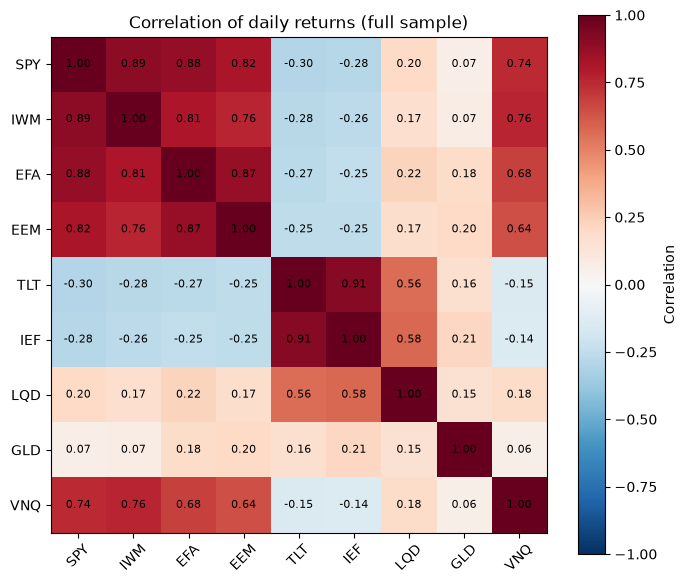

In [10]:
corr = returns.corr()

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(K))
ax.set_yticks(range(K))
ax.set_xticklabels(tickers, rotation=45)
ax.set_yticklabels(tickers)
for i in range(K):
    for j in range(K):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Correlation of daily returns (full sample)")
plt.show()

## 8. Correlations under stress: does diversification hold in a crisis?

The full-sample correlation matrix above summarizes about 22 years of data in a single number per pair. For portfolio construction, however, what matters most is how assets co-move **when markets are under stress**, because that is when diversification is needed. A portfolio built on calm-period correlations may be far riskier in a crash than the model suggests.

We use the two crisis windows defined in section 5 (**2008 financial crisis** and **COVID crash**) and compare each one with **normal times** (the rest of the sample, excluding both crises). We look at **correlations rather than covariances**: in a crisis the volatility of almost every asset spikes, so covariances rise even if the assets do not move more closely together. Correlations remove this scale effect and isolate the change in co-movement.

The analysis has three parts:

1. **Correlation matrices** for normal times, the 2008 crisis and the COVID crash, side by side.
2. **Difference matrices (crisis − normal).** Red cells are pairs that moved more closely together during the crisis (diversification weakened). Blue cells are pairs that diverged (hedging improved).
3. **Rolling 6-month correlation between SPY and TLT**, to check whether the stock–bond relationship is stable over time or changes across market regimes.

Normal times: 5294 days, 2008 crisis: 146 days, COVID crash: 50 days


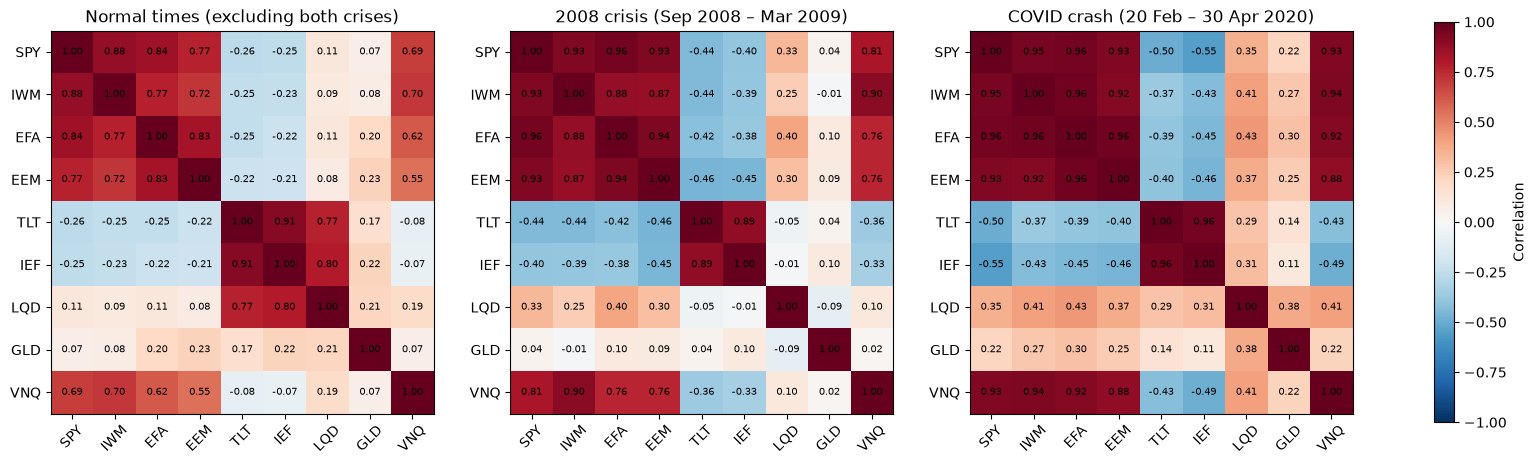

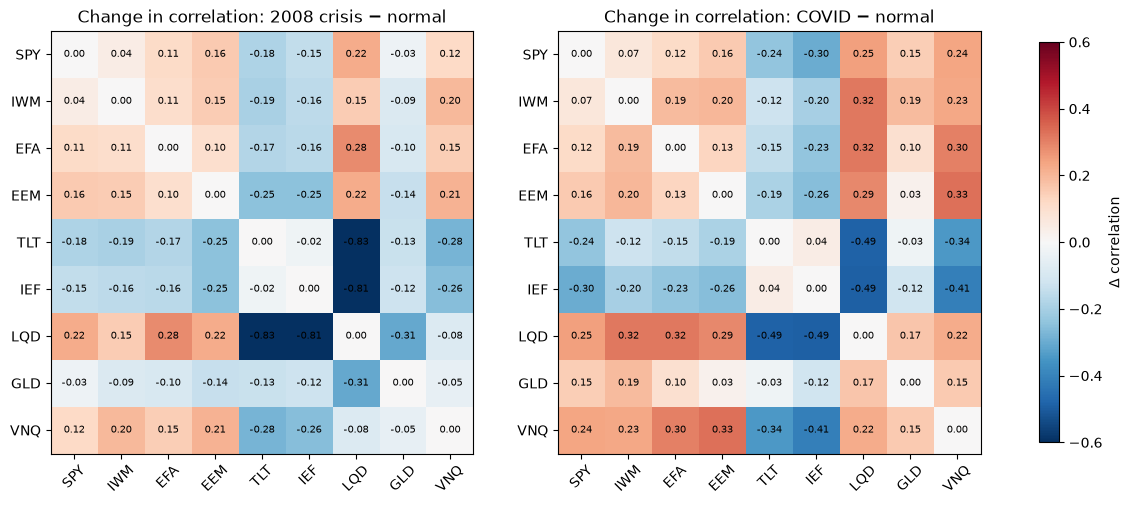

In [11]:
normal = ~(gfc | covid)
corr_normal = returns[normal].corr()
corr_gfc = returns[gfc].corr()
corr_covid = returns[covid].corr()

print(f"Normal times: {normal.sum()} days, 2008 crisis: {gfc.sum()} days, COVID crash: {covid.sum()} days")

def plot_corr(ax, m, title, vmin=-1, vmax=1):
    im = ax.imshow(m, cmap="RdBu_r", vmin=vmin, vmax=vmax)
    ax.set_xticks(range(K))
    ax.set_yticks(range(K))
    ax.set_xticklabels(tickers, rotation=45)
    ax.set_yticklabels(tickers)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f"{m.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
    ax.set_title(title)
    return im

# 1) Normal times vs each crisis
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
plot_corr(axes[0], corr_normal, "Normal times (excluding both crises)")
plot_corr(axes[1], corr_gfc, "2008 crisis (Sep 2008 – Mar 2009)")
im = plot_corr(axes[2], corr_covid, "COVID crash (20 Feb – 30 Apr 2020)")
fig.colorbar(im, ax=axes, label="Correlation", shrink=0.8)
plt.show()

# 2) Differences: what changed during each crisis
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
plot_corr(axes[0], corr_gfc - corr_normal, "Change in correlation: 2008 crisis − normal", vmin=-0.6, vmax=0.6)
im = plot_corr(axes[1], corr_covid - corr_normal, "Change in correlation: COVID − normal", vmin=-0.6, vmax=0.6)
fig.colorbar(im, ax=axes, label="Δ correlation", shrink=0.8)
plt.show()

**Takeaways: correlations during the crises**

- **Treasuries hedged in both crises.** The correlation of SPY with TLT went from −0.26 in normal times to −0.44 in 2008 and −0.50 during COVID (with IEF: −0.25 → −0.40 and −0.55). Investors fled to safety and the Fed cut rates, so Treasuries rallied while stocks fell: in the 2008 window TLT gained 15% while SPY lost 37%.
- **Diversification among risk assets weakened.** The average correlation among equities and REITs (SPY, IWM, EFA, EEM, VNQ) rose from 0.74 in normal times to 0.87 in 2008 and 0.93 during COVID. International and emerging-market stocks, which normally diversify a U.S. portfolio, moved almost one-for-one with SPY in both crises.
- **Corporate bonds behaved like a risk asset.** LQD's correlation with TLT and IEF is about 0.8 in normal times, but it collapsed to about 0 in 2008 and about 0.3 during COVID, while its correlation with SPY rose. When credit risk dominates, investment-grade bonds stop behaving like Treasuries.
- **Gold was a mixed hedge.** In 2008 its correlation with SPY stayed near zero (0.04) and it gained 10% over the window; during COVID its correlation rose from 0.07 to 0.22, consistent with the "sell everything for cash" phase of March 2020.
- **Caveat:** the crisis windows are short (146 and 50 trading days), so these correlations are noisy. They illustrate a pattern rather than give precise estimates, but the pattern is the same in both crises.

The matrices above compare fixed periods. To see how the stock–bond relationship evolves continuously, we compute the correlation between SPY and TLT over a rolling window of 126 trading days (about six months).

In [12]:
# 3) Rolling 6-month correlation between stocks and long bonds
roll = returns["SPY"].rolling(126).corr(returns["TLT"])

fig = go.Figure()
fig.add_trace(go.Scatter(x=roll.index, y=roll, mode="lines", name="SPY–TLT"))

fig.add_hline(y=0, line_dash="dash", line_color="gray")

# 2008 financial crisis
fig.add_vrect(x0="2008-09-01", x1="2009-03-31", fillcolor="purple", opacity=0.15,
              line_width=0, annotation_text="2008 crisis", annotation_position="top left")

# COVID crash
fig.add_vrect(x0="2020-02-20", x1="2020-04-30", fillcolor="red", opacity=0.15,
              line_width=0, annotation_text="COVID crash", annotation_position="top left")

# Fed hiking cycle (inflation shock)
fig.add_vrect(x0="2022-03-16", x1="2023-07-26", fillcolor="orange", opacity=0.15,
              line_width=0, annotation_text="Fed hiking cycle", annotation_position="top left")

fig.update_layout(
    title="SPY–TLT correlation over time (rolling 126-day window)",
    yaxis_title="Correlation (past 126 trading days)",
    height=500,
    xaxis=dict(
        rangeslider=dict(visible=True),
        rangeselector=dict(buttons=[
            dict(count=6, label="6M", step="month", stepmode="backward"),
            dict(count=1, label="1Y", step="year", stepmode="backward"),
            dict(count=3, label="3Y", step="year", stepmode="backward"),
            dict(step="all", label="All"),
        ]),
    ),
)
fig.show()


**Takeaways: the stock–bond correlation is regime-dependent**

The rolling correlation between SPY and TLT tells three stories over the sample. In **2005–2006** it moved around zero. From the **2008 crisis to 2020** it was negative almost continuously (yearly averages between −0.23 and −0.69, with only brief moves near zero in 2013–2014), with its most negative values in 2010–2012 (down to −0.80) and around the 2008 and COVID crashes. It weakened toward zero in 2021. From **2022** it rises: it is mostly positive from 2023 onward, though not monotonically (it dips back toward zero in 2025), and reaches its highest level of the sample (about +0.45) in 2026. (Short dips and spikes should not be over-interpreted: a 6-month rolling window is noisy and lags events by up to six months.)

The sign of the correlation depends on which macro risk dominates:

| Regime | Dominant risk | Bad news leads to… | Stock–bond correlation |
|---|---|---|---|
| ~2000–2021 | Growth (recessions, panics) | Stocks fall, Fed cuts rates, bonds rally | Negative |
| 2022 onward | Inflation and interest rates | High inflation → Fed hikes or holds rates → stocks and bonds fall together | Positive |

The contrast between the two big shocks in the sample is striking: in 2008, a growth shock, TLT gained 34% while SPY lost 37%; in 2022, an inflation shock, the Fed's aggressive hikes hit both asset classes at once and TLT lost 31%. Since then, markets have remained focused on the path of policy rates, and strong economic data can be "bad news" for both stocks and bonds because it implies higher rates for longer. The negative correlation of 2000–2021 is in fact the historical exception: during the inflation-driven 1970s–1990s, the stock–bond correlation was also positive.

Note that the correlation remains mostly positive after the hiking cycle ends in July 2023 (with a temporary return toward zero in 2025). The driver is not the hikes themselves but the fact that inflation and the path of interest rates remained the dominant source of market risk: every inflation or labor-market release shifted rate expectations and moved stocks and bonds in the same direction, both down (higher for longer) and up (e.g. the joint rally of late 2023 when markets anticipated cuts). Long-term yields are also driven by fiscal deficits and Treasury supply, not only by the policy rate. Stock–bond correlation regimes tend to be persistent, which is why we treat 2022 as a regime change rather than a one-off event.

**Implications for the model**

1. A single full-sample covariance matrix averages two very different regimes. Time-varying estimates (rolling window or EWMA) are more appropriate in the backtest.
2. Optimal weights depend on the estimation window. With recent data, TLT looks like a volatile asset that no longer diversifies, while IEF may keep a large weight because of its low volatility.
3. Long-duration Treasuries protect against **growth shocks**, not **inflation shocks**. An effective hedge needs exposures that also work when rates rise.

**Hedging alternatives for an inflation regime**

| Hedge | Example ETFs | Why it can help | Limitation |
|---|---|---|---|
| Gold (already in our universe) | GLD | Historically a store of value during inflation and monetary stress | Can fall in liquidity crunches (e.g. March 2020) and has no cash flows |
| Short-duration Treasuries / T-bills | SGOV, BIL, SHY | Little sensitivity to rate hikes; they benefit from higher yields | Little upside in a crash; mainly reduce risk rather than hedge |
| Inflation-protected bonds (TIPS) | TIP, SCHP; short-duration VTIP | Principal is indexed to inflation | Long TIPS still fell in 2022 as real rates rose; short duration works better |
| Broad commodities | DBC, PDBC | Directly linked to inflation drivers (energy, metals, agriculture); rose strongly in 2022 | Very volatile, long flat periods, roll costs |
| Trend-following / managed futures | DBMF, KMLM | Can go long or short across assets; delivered strong positive returns in 2022 when stocks and bonds fell together | Strategy risk, higher fees, can underperform for years |
| Explicit tail protection | Put options, long-volatility strategies | Pay off directly in crashes | Costly to hold over time (negative carry) |

**Possible extensions:** (i) add one or two of these assets (e.g. SGOV, TIP or DBC) to the universe and check how the efficient portfolios change; (ii) estimate the minimum-variance portfolio on 2008–2021 data and evaluate it out of sample on 2022–2026 to measure the cost of assuming a stable covariance matrix.

## 9. Summary of findings and next steps

**What we learned from the data**

1. **Clean data:** 9 ETFs with complete daily prices from January 2005 to October 2026 (5,490 daily log returns, no missing values). The sample includes the 2008 financial crisis, the COVID crash and the 2022 inflation shock.
2. **Returns are not normal.** All assets show fat tails, and most risky assets show negative skew. Most of the fat tails come from the 2008 crisis (and, to a lesser extent, COVID), so sample skewness and kurtosis are unstable and are used as diagnostics only.
3. **Historical means are period-dependent.** Treasuries earned much of their return during the crises, and lost heavily in 2022. Historical means are a weak guide to expected returns.
4. **Diversification weakens in a crisis.** In both 2008 and COVID, equities and REITs became much more correlated with each other and corporate bonds stopped behaving like Treasuries. Treasuries (TLT, IEF) hedged in both crises; gold hedged in 2008 but not during COVID.
5. **The stock–bond correlation depends on the regime.** It was negative from 2008 to 2021 (growth-driven market) and has been mostly positive since 2022 (inflation- and rate-driven market). A single full-sample covariance matrix mixes both regimes.

**Next steps for the optimization notebooks**

- Start with the **minimum-variance portfolio**, which only needs $\Sigma$, then add constraints (e.g. no short sales).
- Estimate $\Sigma$ with a **rolling 3-year window** (756 trading days), so the estimates adapt to regime changes.
- Run an **out-of-sample backtest with monthly rebalancing**. With a 3-year estimation window, the test period starts in early 2008 and includes the 2008 crisis, COVID and the 2022 regime change.
- Evaluate portfolios with **volatility, Sharpe ratio, maximum drawdown and turnover**, since the normal distribution understates tail risk.

**Questions to keep in mind**

1. Which asset had the **lowest** annualized volatility? Do you expect it to get a large weight in the minimum-variance portfolio? Why might the correlations change that answer?
2. Which pairs have the **highest** correlations (above ~0.8)? Remember the hedge example: high correlation + different volatilities is where the formula wants to short.
3. Which pairs have **negative or near-zero** correlations? Those are the diversifiers, and how stable are they across regimes?